# Component 1: AI Waste Classification
J26-ISE-305 - Intelligent Waste Management System for Sri Lanka


## Step 1. Setup

In [1]:
import os, shutil, random, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support
from PIL import Image
from pathlib import Path

!pip -q install huggingface_hub

CLASSES = ["plastic", "paper", "glass", "metal", "organic"]
IMG_SIZE = (224, 224)
BATCH = 32
SEED = 42

random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print("GPU found:", len(tf.config.list_physical_devices("GPU")) > 0)

GPU found: True


## Step 2. Get the public datasets
Downloads the garbage dataset automatically, then upload `trashnet.zip` (from the `data` folder).

In [2]:
from huggingface_hub import snapshot_download
from google.colab import files

snapshot_download("omasteam/waste-garbage-management-dataset", repo_type="dataset",
                  local_dir="/content/downloads/garbage")
print("garbage dataset downloaded")

print("Now upload trashnet.zip")
uploaded = files.upload()
for zip_name in uploaded:
    with zipfile.ZipFile(zip_name) as z:
        z.extractall("/content/downloads/" + Path(zip_name).stem)
    print("unzipped:", zip_name)

garbage dataset downloaded
Now upload trashnet.zip


Saving trashnet.zip to trashnet.zip
unzipped: trashnet.zip


## Step 3. Sort photos into the 5 groups
cardboard -> paper, biological -> organic. Other folders (clothes, shoes, trash...) are skipped.

In [3]:
FOLDER_TO_CLASS = {"plastic": "plastic", "paper": "paper", "cardboard": "paper", "glass": "glass",
                   "metal": "metal", "biological": "organic"}
IMAGE_TYPES = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

PUBLIC = Path("/content/data/public")
for c in CLASSES:
    (PUBLIC / c).mkdir(parents=True, exist_ok=True)

def save_small(old_path, new_path):
    img = Image.open(old_path).convert("RGB")
    img.thumbnail((384, 384))
    img.save(new_path, "JPEG")

for dataset in sorted(Path("/content/downloads").iterdir()):
    for folder in dataset.rglob("*"):
        if folder.is_dir() and folder.name.lower() in FOLDER_TO_CLASS:
            group = FOLDER_TO_CLASS[folder.name.lower()]
            for photo in folder.rglob("*"):
                if photo.suffix.lower() in IMAGE_TYPES:
                    try:
                        save_small(photo, PUBLIC / group / (dataset.name + "_" + folder.name + "_" + photo.stem + ".jpg"))
                    except Exception:
                        pass
    print("sorted:", dataset.name)

for c in CLASSES:
    print(c, ":", len(list((PUBLIC / c).glob("*.jpg"))))

sorted: garbage
sorted: trashnet
plastic : 2458
paper : 4499
glass : 3555
metal : 1426
organic : 997


## Step 4. Sri Lankan photos 

In [4]:
from google.colab import files

LOCAL = Path("/content/data/local")
for c in CLASSES:
    (LOCAL / c).mkdir(parents=True, exist_ok=True)

answer = input("Upload local.zip with Sri Lankan photos? (y/n): ")
if answer.strip().lower() == "y":
    uploaded = files.upload()
    with zipfile.ZipFile(list(uploaded.keys())[0]) as z:
        z.extractall("/content/data/local_unzipped")

    for photo in Path("/content/data/local_unzipped").rglob("*"):
        if photo.suffix.lower() in IMAGE_TYPES and photo.parent.name in CLASSES:
            save_small(photo, LOCAL / photo.parent.name / ("local_" + photo.stem + ".jpg"))

for c in CLASSES:
    print(c, "- Sri Lankan photos:", len(list((LOCAL / c).glob("*.jpg"))))

Upload local.zip with Sri Lankan photos? (y/n): n
plastic - Sri Lankan photos: 0
paper - Sri Lankan photos: 0
glass - Sri Lankan photos: 0
metal - Sri Lankan photos: 0
organic - Sri Lankan photos: 0


## Step 5. Train / Validation / Test split (70 / 15 / 15)
Exact duplicate photos are removed first, so the same photo cannot be in both train and test.

In [5]:
import hashlib

SPLIT = Path("/content/data/split")
if SPLIT.exists():
    shutil.rmtree(SPLIT)

seen = set()
photos_by_class = {}
removed = 0
for c in CLASSES:
    photos_by_class[c] = []
    for p in list((PUBLIC / c).glob("*.jpg")) + list((LOCAL / c).glob("*.jpg")):
        key = hashlib.md5(p.read_bytes()).hexdigest()
        if key in seen:
            removed += 1
            continue
        seen.add(key)
        photos_by_class[c].append(p)
print("duplicate photos removed:", removed)

counts = {c: len(photos_by_class[c]) for c in CLASSES}
print(counts)
empty = [c for c, n in counts.items() if n < 10]
if empty:
    raise SystemExit("Too few photos for: " + ", ".join(empty) + ". Run Steps 2 to 4 again.")

for c in CLASSES:
    train, rest = train_test_split(photos_by_class[c], test_size=0.30, random_state=SEED)
    val, test = train_test_split(rest, test_size=0.50, random_state=SEED)
    for part_name, part in [("train", train), ("val", val), ("test", test)]:
        folder = SPLIT / part_name / c
        folder.mkdir(parents=True, exist_ok=True)
        for p in part:
            shutil.copy(p, folder / p.name)

for part_name in ["train", "val", "test"]:
    total = sum(len(list((SPLIT / part_name / c).glob("*.jpg"))) for c in CLASSES)
    print(part_name, ":", total, "photos")

duplicate photos removed: 2390
{'plastic': 1976, 'paper': 3502, 'glass': 3055, 'metal': 1015, 'organic': 997}
train : 7379 photos
val : 1581 photos
test : 1585 photos


## Step 6. Load the photos

In [6]:
def load(part, shuffle):
    return keras.utils.image_dataset_from_directory(
        SPLIT / part, label_mode="categorical", class_names=CLASSES,
        image_size=IMG_SIZE, batch_size=BATCH, shuffle=shuffle, seed=SEED)

train_data = load("train", True)
val_data = load("val", False)
test_data = load("test", False)

Found 7379 files belonging to 5 classes.
Found 1581 files belonging to 5 classes.
Found 1585 files belonging to 5 classes.


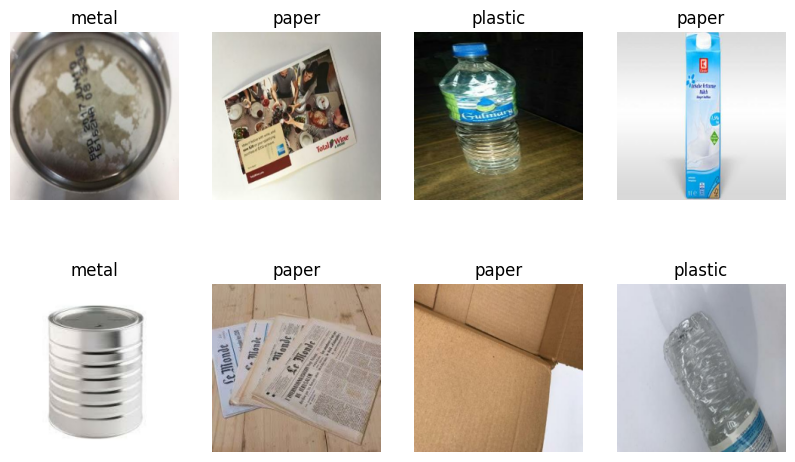

In [7]:
plt.figure(figsize=(10, 6))
for images, labels in train_data.take(1):
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(CLASSES[np.argmax(labels[i])])
        plt.axis("off")
plt.show()

## Step 7. Data augmentation

In [8]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.2),
    layers.RandomBrightness(0.25),
    layers.RandomContrast(0.25),
])

## Step 8. Model 1 - Baseline CNN

In [9]:
baseline = keras.Sequential([
    layers.Input(IMG_SIZE + (3,)),
    augment,
    layers.Rescaling(1 / 255),
    layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dropout(0.4),
    layers.Dense(128, activation="relu"),
    layers.Dense(len(CLASSES), activation="softmax"),
])
baseline.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

stop_early = keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True)
HISTORIES = {}
history_baseline = baseline.fit(train_data, validation_data=val_data, epochs=20, callbacks=[stop_early])
HISTORIES['Baseline CNN'] = history_baseline.history

Epoch 1/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 24s 68ms/step - accuracy: 0.4690 - loss: 1.3168 - val_accuracy: 0.5357 - val_loss: 1.1474
Epoch 2/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 15s 63ms/step - accuracy: 0.5555 - loss: 1.1049 - val_accuracy: 0.5560 - val_loss: 1.0531
Epoch 3/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 15s 63ms/step - accuracy: 0.5875 - loss: 1.0257 - val_accuracy: 0.5617 - val_loss: 1.0585
Epoch 4/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 15s 64ms/step - accuracy: 0.6043 - loss: 0.9768 - val_accuracy: 0.6028 - val_loss: 1.0089
Epoch 5/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 16s 69ms/step - accuracy: 0.6331 - loss: 0.9249 - val_accuracy: 0.6553 - val_loss: 0.8844
Epoch 6/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 16s 69ms/step - accuracy: 0.6504 - loss: 0.8890 - val_accuracy: 0.6243 - val_loss: 0.9666
Epoch 7/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 15s 66ms/step - accuracy: 0.6699 - loss: 0.8382 - val_accuracy: 0.6818 - val_loss: 0.8672
Epoch 8/20
231/231 ━━━━━━━━━━━━━━━━━━━━ 16s 71ms/step - accuracy: 0.6887 - loss: 0.8074 - 

## Step 9. Models 2 and 3 - Transfer learning
MobileNetV2 and EfficientNetB0, trained in two phases (frozen, then fine-tuned).

In [10]:
def make_transfer_model(which):

    if which == "mobilenet":
        base = keras.applications.MobileNetV2(include_top=False, weights="imagenet", input_shape=IMG_SIZE + (3,))
        prepare = layers.Rescaling(1 / 127.5, offset=-1)
    else:
        base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet", input_shape=IMG_SIZE + (3,))
        prepare = layers.Identity()
    base.trainable = False

    inputs = keras.Input(IMG_SIZE + (3,))
    x = augment(inputs)
    x = prepare(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(len(CLASSES), activation="softmax")(x)
    return keras.Model(inputs, outputs), base

def train_transfer_model(which, train_set, name):
    model, base = make_transfer_model(which)

    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="categorical_crossentropy", metrics=["accuracy"])
    h1 = model.fit(train_set, validation_data=val_data, epochs=10,
              callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)])

    base.trainable = True
    for layer in base.layers[:-30]:
        layer.trainable = False
    model.compile(optimizer=keras.optimizers.Adam(1e-5), loss="categorical_crossentropy", metrics=["accuracy"])
    h2 = model.fit(train_set, validation_data=val_data, epochs=10,
              callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)])
    HISTORIES[name] = {k: h1.history[k] + h2.history[k] for k in h1.history}
    return model

In [11]:
mobilenet = train_transfer_model("mobilenet", train_data, "MobileNetV2")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 26s 90ms/step - accuracy: 0.7631 - loss: 0.6446 - val_accuracy: 0.8912 - val_loss: 0.3130
Epoch 2/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 17s 73ms/step - accuracy: 0.8549 - loss: 0.3985 - val_accuracy: 0.9108 - val_loss: 0.2728
Epoch 3/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 17s 73ms/step - accuracy: 0.8748 - loss: 0.3530 - val_accuracy: 0.9127 - val_loss: 0.2622
Epoch 4/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 20s 73ms/step - accuracy: 0.8793 - loss: 0.3363 - val_accuracy: 0.9184 - val_loss: 0.2420
Epoch 5/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 19s 83ms/step - accuracy: 0.8843 - loss: 0.3254 - val_accuracy: 0.9140 - val_loss: 0.2559
Epoch 6/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 19s 84ms/step - accuracy: 0.8879 - loss: 0.3250 - val_accuracy: 0.9228 - val_loss: 0.2296
Epoch 7/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 19s 83ms/step - accuracy: 0.8882 - loss: 0.3077 - val_accuracy: 0.9241 - val_loss: 0.2307
Epoch 8/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 1

In [12]:
efficientnet = train_transfer_model("efficientnet", train_data, "EfficientNetB0")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 35s 113ms/step - accuracy: 0.8051 - loss: 0.5571 - val_accuracy: 0.9114 - val_loss: 0.2778
Epoch 2/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 22s 97ms/step - accuracy: 0.8882 - loss: 0.3207 - val_accuracy: 0.9247 - val_loss: 0.2225
Epoch 3/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 41s 97ms/step - accuracy: 0.8999 - loss: 0.2853 - val_accuracy: 0.9304 - val_loss: 0.2032
Epoch 4/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 23s 99ms/step - accuracy: 0.9065 - loss: 0.2626 - val_accuracy: 0.9298 - val_loss: 0.1940
Epoch 5/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 22s 96ms/step - accuracy: 0.9107 - loss: 0.2483 - val_accuracy: 0.9311 - val_loss: 0.1856
Epoch 6/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 22s 95ms/step - accuracy: 0.9145 - loss: 0.2438 - val_accuracy: 0.9298 - val_loss: 0.1875
Epoch 7/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 24s 102ms/step - accuracy: 0.9148 - loss: 0.2290 - val_accuracy: 0.9336 - val_loss: 0.1798
Epoch 8/10
231/231 ━━━━━━━━━━━━━━━━━━

## Step 10. Test the models


===== Baseline CNN =====
accuracy : 0.779 (target 0.90)
precision: 0.751 (target 0.85)
recall   : 0.749 (target 0.85)
f1-score : 0.747 (target 0.87)
              precision    recall  f1-score   support

     plastic       0.81      0.70      0.75       297
       paper       0.81      0.84      0.83       526
       glass       0.79      0.81      0.80       459
       metal       0.63      0.54      0.58       153
     organic       0.72      0.85      0.78       150

    accuracy                           0.78      1585
   macro avg       0.75      0.75      0.75      1585
weighted avg       0.78      0.78      0.78      1585



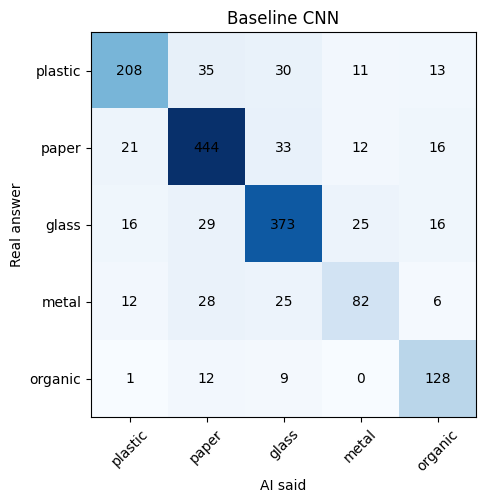

===== MobileNetV2 =====
accuracy : 0.927 (target 0.90)
precision: 0.909 (target 0.85)
recall   : 0.928 (target 0.85)
f1-score : 0.918 (target 0.87)
              precision    recall  f1-score   support

     plastic       0.90      0.89      0.89       297
       paper       0.98      0.95      0.97       526
       glass       0.93      0.92      0.92       459
       metal       0.80      0.90      0.85       153
     organic       0.94      0.99      0.96       150

    accuracy                           0.93      1585
   macro avg       0.91      0.93      0.92      1585
weighted avg       0.93      0.93      0.93      1585



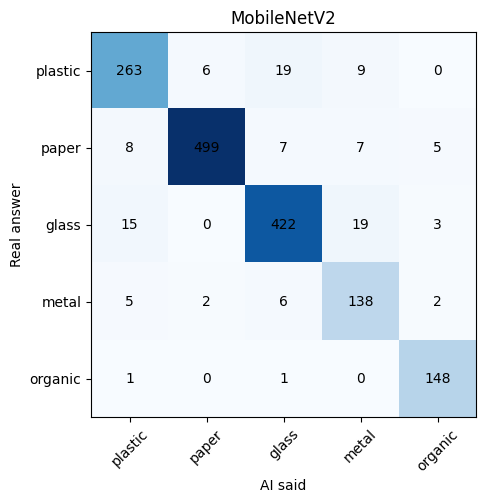

===== EfficientNetB0 =====
accuracy : 0.938 (target 0.90)
precision: 0.933 (target 0.85)
recall   : 0.934 (target 0.85)
f1-score : 0.933 (target 0.87)
              precision    recall  f1-score   support

     plastic       0.89      0.91      0.90       297
       paper       0.97      0.97      0.97       526
       glass       0.94      0.92      0.93       459
       metal       0.89      0.88      0.88       153
     organic       0.97      0.99      0.98       150

    accuracy                           0.94      1585
   macro avg       0.93      0.93      0.93      1585
weighted avg       0.94      0.94      0.94      1585



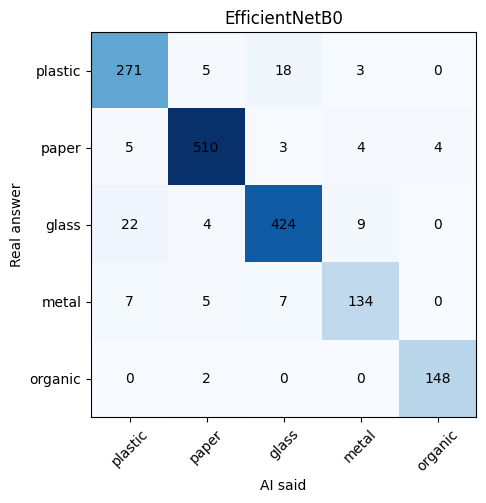

In [13]:
results = []

def test_model(name, model, show_matrix=True):

    y_true = np.concatenate([np.argmax(labels, axis=1) for _, labels in test_data])
    y_pred = np.argmax(model.predict(test_data, verbose=0), axis=1)

    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    row = {"model": name, "accuracy": acc, "precision": prec, "recall": rec, "f1": f1}

    files_in_test = [os.path.basename(f) for f in test_data.file_paths]
    is_local = np.array([f.startswith("local_") for f in files_in_test])
    if is_local.sum() > 0:
        row["sri_lanka_accuracy"] = accuracy_score(y_true[is_local], y_pred[is_local])
    results.append(row)

    print("=====", name, "=====")
    print("accuracy :", round(acc, 3), "(target 0.90)")
    print("precision:", round(prec, 3), "(target 0.85)")
    print("recall   :", round(rec, 3), "(target 0.85)")
    print("f1-score :", round(f1, 3), "(target 0.87)")
    print(classification_report(y_true, y_pred, target_names=CLASSES, zero_division=0))

    if show_matrix:
        matrix = confusion_matrix(y_true, y_pred)
        plt.figure(figsize=(6, 5))
        plt.imshow(matrix, cmap="Blues")
        plt.xticks(range(len(CLASSES)), CLASSES, rotation=45)
        plt.yticks(range(len(CLASSES)), CLASSES)
        for i in range(len(CLASSES)):
            for j in range(len(CLASSES)):
                plt.text(j, i, matrix[i, j], ha="center", va="center")
        plt.xlabel("AI said")
        plt.ylabel("Real answer")
        plt.title(name)
        plt.show()

test_model("Baseline CNN", baseline)
test_model("MobileNetV2", mobilenet)
test_model("EfficientNetB0", efficientnet)

In [14]:
pd.DataFrame(results).round(3)

,model,accuracy,precision,recall,f1
0,Baseline CNN,0.779,0.751,0.749,0.747
1,MobileNetV2,0.927,0.909,0.928,0.918
2,EfficientNetB0,0.938,0.933,0.934,0.933


## Step 10b. Training curves and model comparison

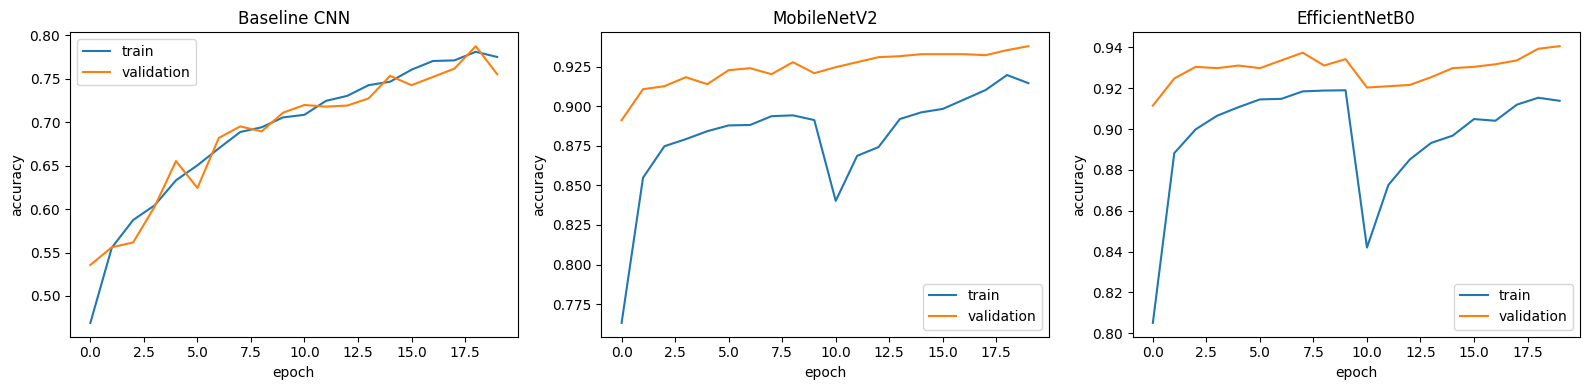

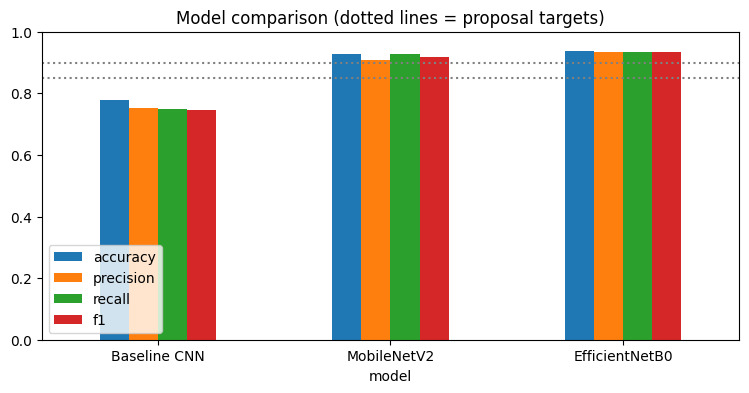

Best model: EfficientNetB0


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, h) in zip(axes, [(k, v) for k, v in HISTORIES.items() if "public only" not in k]):
    ax.plot(h["accuracy"], label="train")
    ax.plot(h["val_accuracy"], label="validation")
    ax.set_title(name)
    ax.set_xlabel("epoch")
    ax.set_ylabel("accuracy")
    ax.legend()
plt.tight_layout()
plt.show()

table = pd.DataFrame(results).set_index("model")[["accuracy", "precision", "recall", "f1"]]
ax = table.plot.bar(figsize=(9, 4), ylim=(0, 1), rot=0)
for target in (0.90, 0.85):
    ax.axhline(target, color="grey", linestyle=":")
ax.set_title("Model comparison (dotted lines = proposal targets)")
plt.show()

best_name = table["f1"].idxmax()
print("Best model:", best_name)

### Wrong predictions (what does the best model get wrong?)

wrong: 98 of 1585


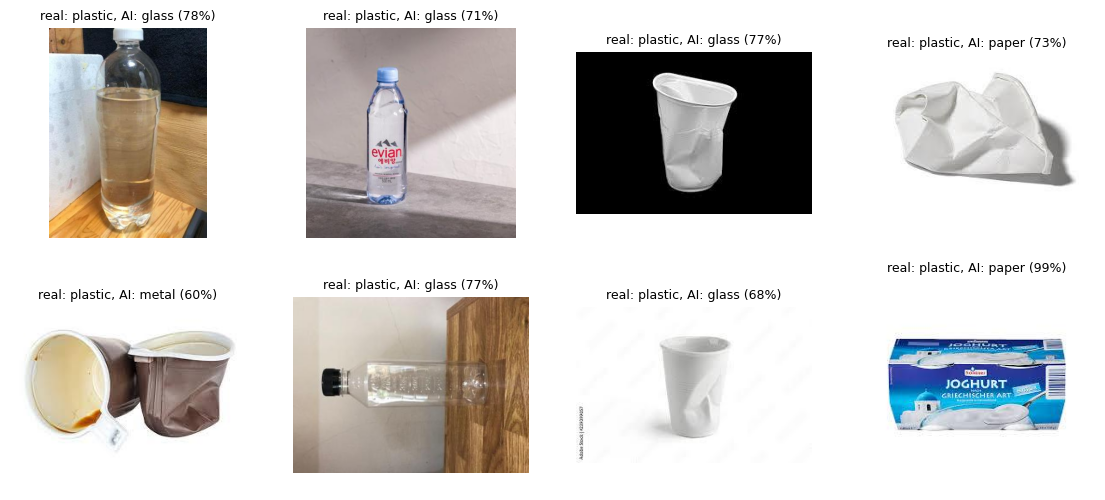

In [16]:
MODELS = {"Baseline CNN": baseline, "MobileNetV2": mobilenet, "EfficientNetB0": efficientnet}
best_model = MODELS[best_name]

paths = np.array(test_data.file_paths)
y_true = np.concatenate([np.argmax(l, axis=1) for _, l in test_data])
probs = best_model.predict(test_data, verbose=0)
y_pred = probs.argmax(axis=1)
wrong = np.where(y_pred != y_true)[0]
print("wrong:", len(wrong), "of", len(y_true))

plt.figure(figsize=(14, 6))
for k, i in enumerate(wrong[:8]):
    plt.subplot(2, 4, k + 1)
    plt.imshow(Image.open(paths[i]))
    plt.title("real: %s, AI: %s (%.0f%%)" % (CLASSES[y_true[i]], CLASSES[y_pred[i]], probs[i].max() * 100), fontsize=9)
    plt.axis("off")
plt.show()

## Step 11. Do Sri Lankan photos help?
Train MobileNetV2 without the `local_` photos and compare on the same test set.

In [17]:
PUBLIC_ONLY = Path("/content/data/train_public_only")
if PUBLIC_ONLY.exists():
    shutil.rmtree(PUBLIC_ONLY)
shutil.copytree(SPLIT / "train", PUBLIC_ONLY)

removed = 0
for photo in PUBLIC_ONLY.rglob("local_*"):
    photo.unlink()
    removed += 1
print("Sri Lankan photos removed from training:", removed)

train_public_only = keras.utils.image_dataset_from_directory(
    PUBLIC_ONLY, label_mode="categorical", class_names=CLASSES,
    image_size=IMG_SIZE, batch_size=BATCH, shuffle=True, seed=SEED)

Sri Lankan photos removed from training: 0
Found 7379 files belonging to 5 classes.


In [18]:
mobilenet_public_only = train_transfer_model("mobilenet", train_public_only, "MobileNetV2 - public only")

Epoch 1/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 26s 89ms/step - accuracy: 0.7557 - loss: 0.6687 - val_accuracy: 0.8906 - val_loss: 0.3087
Epoch 2/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 17s 74ms/step - accuracy: 0.8576 - loss: 0.3949 - val_accuracy: 0.9058 - val_loss: 0.2724
Epoch 3/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 19s 83ms/step - accuracy: 0.8790 - loss: 0.3478 - val_accuracy: 0.9102 - val_loss: 0.2623
Epoch 4/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 17s 72ms/step - accuracy: 0.8837 - loss: 0.3331 - val_accuracy: 0.9146 - val_loss: 0.2456
Epoch 5/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 21s 73ms/step - accuracy: 0.8858 - loss: 0.3297 - val_accuracy: 0.9235 - val_loss: 0.2292
Epoch 6/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 17s 74ms/step - accuracy: 0.8906 - loss: 0.3105 - val_accuracy: 0.9197 - val_loss: 0.2397
Epoch 7/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 17s 73ms/step - accuracy: 0.8885 - loss: 0.3094 - val_accuracy: 0.9171 - val_loss: 0.2338
Epoch 8/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 17s 72ms/step - accuracy: 0.8914 - loss: 0.3015 - 

In [19]:
test_model("MobileNetV2 - public only", mobilenet_public_only, show_matrix=False)
test_model("MobileNetV2 - public + Sri Lankan", mobilenet, show_matrix=False)
pd.DataFrame(results).round(3).tail(2)

===== MobileNetV2 - public only =====
accuracy : 0.93 (target 0.90)
precision: 0.913 (target 0.85)
recall   : 0.932 (target 0.85)
f1-score : 0.922 (target 0.87)
              precision    recall  f1-score   support

     plastic       0.92      0.88      0.90       297
       paper       0.98      0.96      0.97       526
       glass       0.93      0.92      0.92       459
       metal       0.80      0.92      0.85       153
     organic       0.94      0.99      0.97       150

    accuracy                           0.93      1585
   macro avg       0.91      0.93      0.92      1585
weighted avg       0.93      0.93      0.93      1585

===== MobileNetV2 - public + Sri Lankan =====
accuracy : 0.927 (target 0.90)
precision: 0.909 (target 0.85)
recall   : 0.928 (target 0.85)
f1-score : 0.918 (target 0.87)
              precision    recall  f1-score   support

     plastic       0.90      0.89      0.89       297
       paper       0.98      0.95      0.97       526
       glass     

,model,accuracy,precision,recall,f1
3,MobileNetV2 - public only,0.930,0.913,0.932,0.922
4,MobileNetV2 - public + Sri Lankan,0.927,0.909,0.928,0.918


## Step 11b. Confidence threshold 

In [20]:
conf = probs.max(axis=1)
rows = []
for t in [0.0, 0.5, 0.6, 0.7, 0.8, 0.9]:
    keep = conf >= t
    rows.append({"threshold": t,
                 "answered": round(keep.mean(), 3),
                 "accuracy_when_answered": round(accuracy_score(y_true[keep], y_pred[keep]), 3) if keep.any() else None})
pd.DataFrame(rows)

,threshold,answered,accuracy_when_answered
0,0.0,1.000,0.938
1,0.5,0.980,0.948
2,0.6,0.948,0.961
3,0.7,0.914,0.970
4,0.8,0.862,0.984
5,0.9,0.801,0.988


In [21]:
import time
sample = tf.random.uniform((1, 224, 224, 3), 0, 255)
best_model.predict(sample, verbose=0)           # warm up
start = time.perf_counter()
for _ in range(20):
    best_model.predict(sample, verbose=0)
print("Time for one photo: %.0f ms" % ((time.perf_counter() - start) / 20 * 1000))

Time for one photo: 76 ms


## Step 12. Save the models

In [22]:
os.makedirs("/content/saved_models", exist_ok=True)
baseline.save("/content/saved_models/baseline_cnn.keras")
mobilenet.save("/content/saved_models/mobilenetv2.keras")
efficientnet.save("/content/saved_models/efficientnetb0.keras")
mobilenet_public_only.save("/content/saved_models/mobilenetv2_public_only.keras")
pd.DataFrame(results).round(3).to_csv("/content/saved_models/results.csv", index=False)

best_model.save("/content/saved_models/best_model.keras")

import json
json.dump(CLASSES, open("/content/saved_models/class_names.json", "w"))

try:   # small file for phones
    converter = tf.lite.TFLiteConverter.from_keras_model(best_model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    open("/content/saved_models/best_model.tflite", "wb").write(converter.convert())
except Exception as error:
    print("TFLite export skipped:", error)
print("best model:", best_name)

shutil.make_archive("/content/component1_results", "zip", "/content/saved_models")
files.download("/content/component1_results.zip")

best model: EfficientNetB0
